🥇 Project 1 — California Housing Price Prediction
Dataset: California Housing — scikit-learn

Size: 20,640 observations, 8 numerical features. GitHub

Algorithms: Linear Regression → Ridge Regression

Suggested duration: 5–7 days
Your objective
Predict the median house value of a California census block group using features such as median income, house age, and average number of rooms.

This is a regression problem because the target is continuous.
What you'll practice
1. Understanding the dataset and its variables.
2. Performing exploratory data analysis (EDA).
3. Identifying outliers and investigating feature distributions.
4. Splitting data into training and testing sets.
5. Training a linear regression model.
6. Evaluating predictions using MAE, RMSE, and \(R^2\).
7. Comparing ordinary linear regression with Ridge regression.

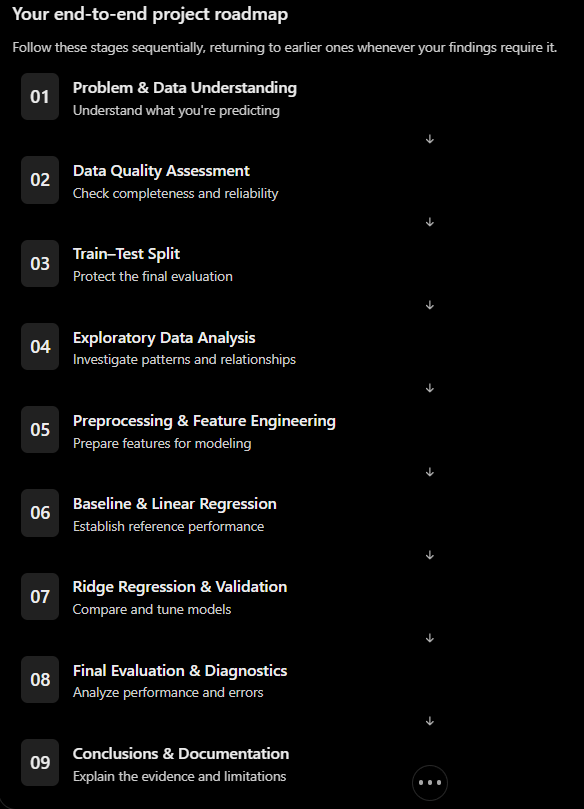

Project: California Housing Price Prediction

Problem: Predict the median house value of a California census block group.

Observation unit: One census block group.

Target: MedHouseVal

ML type: Supervised regression.

Success criteria: Create an explainable baseline and outperform a simple constant predictor on unseen data.

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

RANDOM_STATE = 42


### 1.Problem and Data Understanding

In [2]:
housing = fetch_california_housing(as_frame=True)
housing.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [3]:
target = housing['target']
target.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [4]:
df = housing['frame']
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
df.shape

(20640, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [8]:
df.duplicated().sum()

0

In [9]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [10]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [11]:
df.describe(include='all')

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


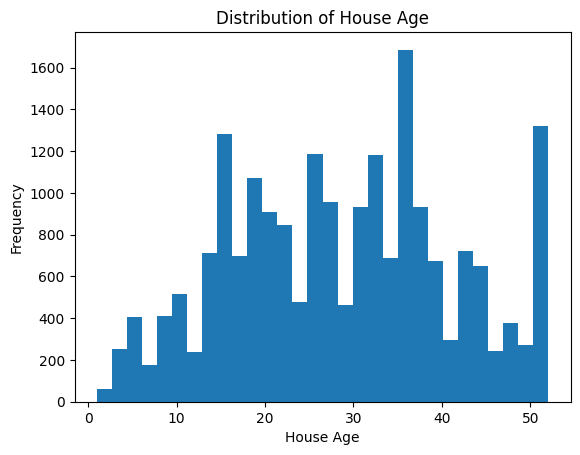

In [12]:
plt.hist(df['HouseAge'],bins=30)
plt.title("Distribution of House Age")
plt.ylabel('Frequency')
plt.xlabel('House Age')
plt.show()


### 03-Train test Split


In [18]:
X = housing['data']
y = housing['target']
print(X.shape)
print(y.shape)

(20640, 8)
(20640,)


In [20]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE)
print('Training samples:',len(X_train))
print('Test samples:',len(X_test))

Training samples: 16512
Test samples: 4128


In [ ]:
### Optional ->Validation
X_val,X_test,y_val,y_test = train_test_split(X_test,y_test,test_size=0.5,random_state=RANDOM_STATE,stratify=y_test)

### 04.EDA

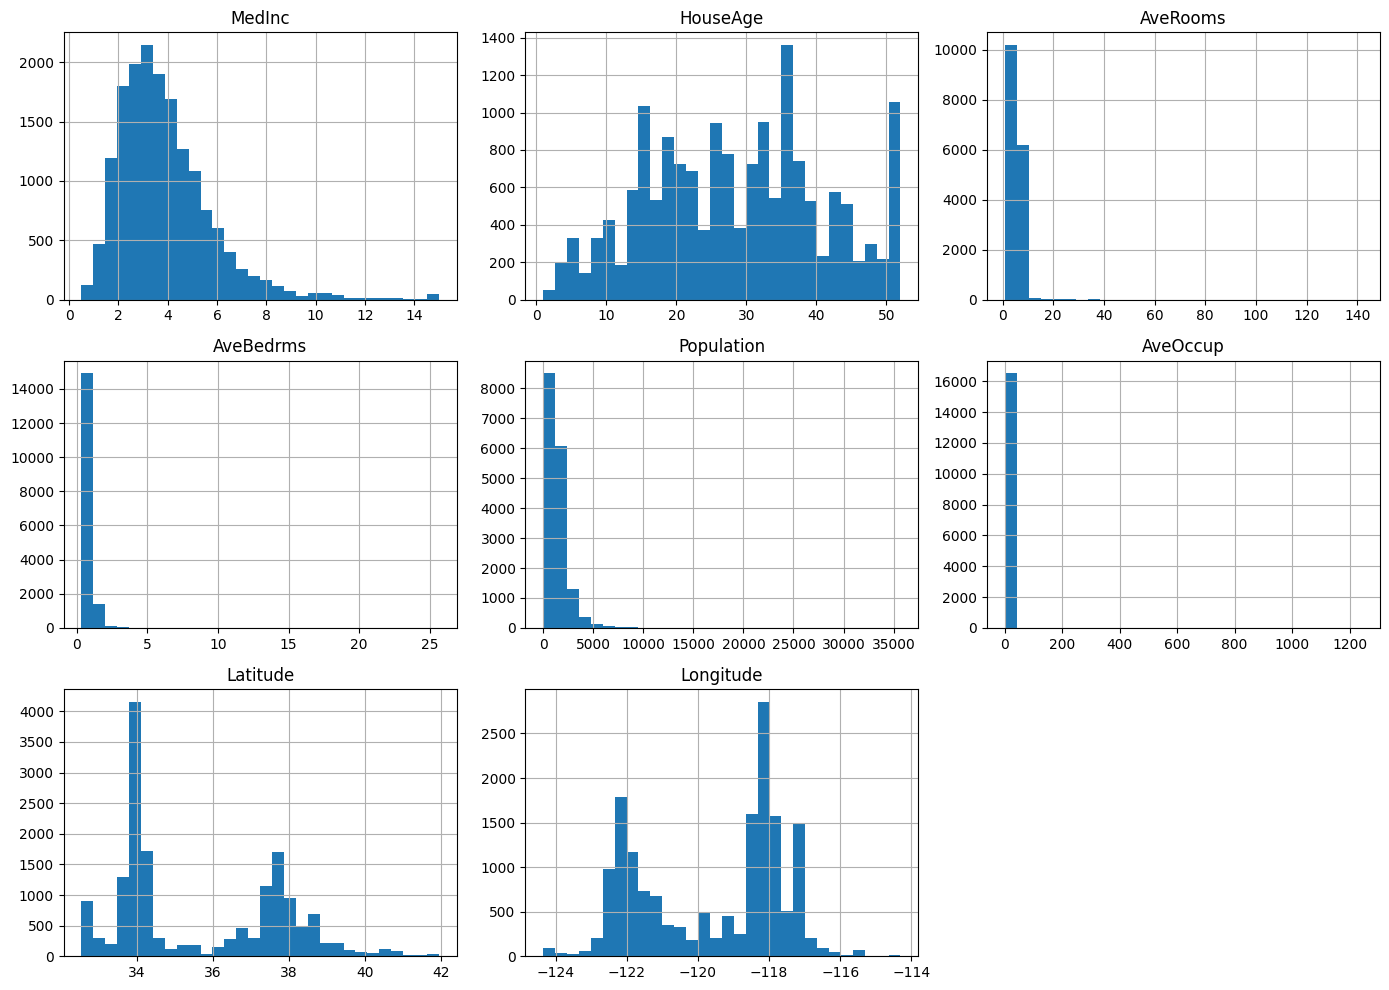

In [22]:
### Let's start with exploring feature distributions
X_train.hist(figsize=(14,10),bins=30)
plt.tight_layout()
plt.show()

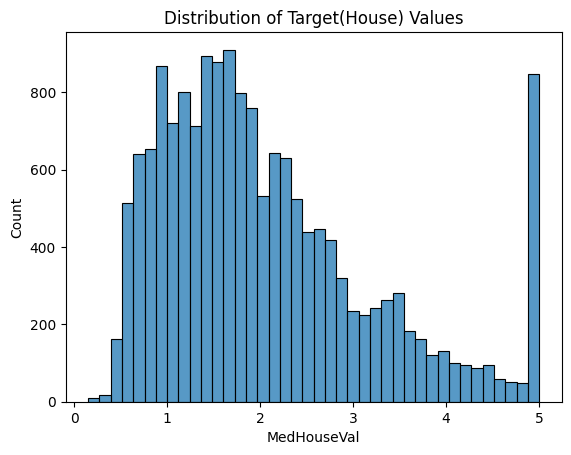

In [24]:
sns.histplot(x=y_train,bins=40)
plt.title('Distribution of Target(House) Values')
plt.show()

In [45]:
# df['AveOccup'].plot(kind='box')

q1 = np.percentile(df['AveOccup'],25)
q3 = np.percentile(df['AveOccup'],75)
iqr = q3-q1

low_bound = q1-1.5*iqr
up_bound = q3+1.5*iqr
outliers = df[(df['AveOccup']<low_bound)|(df['AveOccup']>up_bound)]
print("Outlier count:",len(outliers))

Outlier count: 711


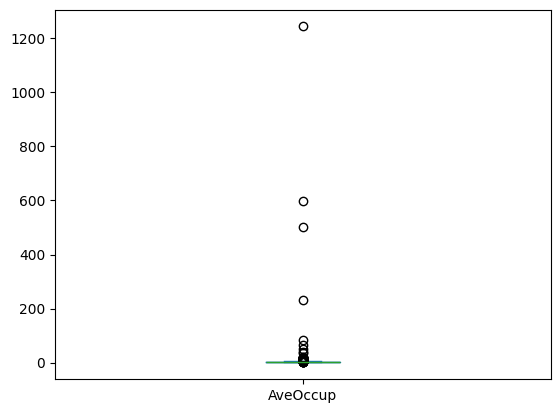

In [41]:
df['AveOccup'].plot(kind='box')
plt.show()

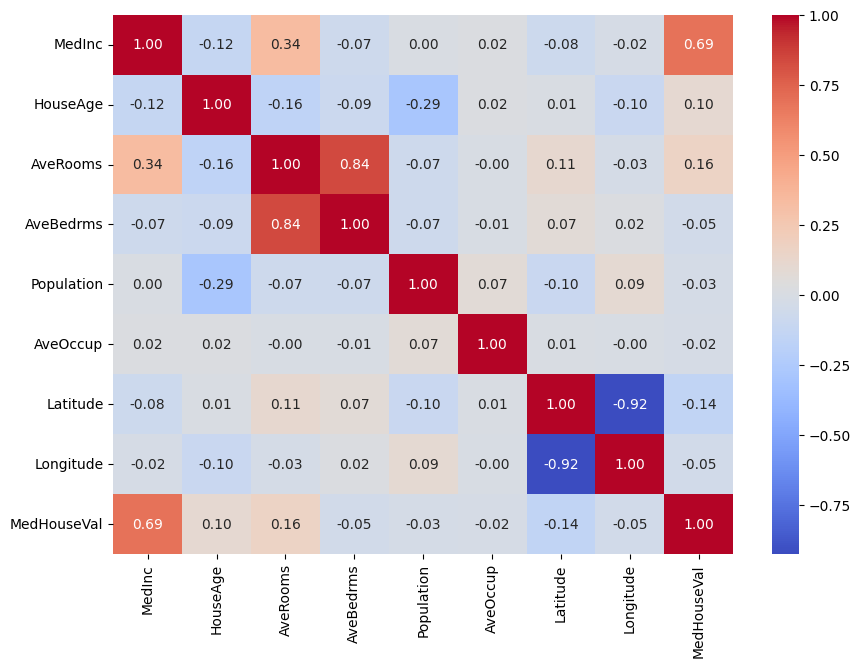

In [32]:
### Correlation analysis
train_df = X_train.copy()
train_df['MedHouseVal'] = y_train

corr = train_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()